In [1]:
import sys
print(sys.version)

3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully")


All libraries imported successfully


In [4]:
import os
os.getcwd()


'C:\\Users\\kumbh'

In [5]:
os.chdir(r"C:\Users\kumbh\Documents\GSE123966_RNAseq")
os.getcwd()


'C:\\Users\\kumbh\\Documents\\GSE123966_RNAseq'

In [6]:
os.listdir("data")


['GSE123966_ReverseStrandedCounts-withNames-proteinCoding.txt.gz']

In [7]:
import gzip
import shutil

input_file = "data/GSE123966_ReverseStrandedCounts-withNames-proteinCoding.txt.gz"
output_file = "data/GSE123966_ReverseStrandedCounts-withNames-proteinCoding.txt"

with gzip.open(input_file, "rb") as f_in:
    with open(output_file, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

print("Extraction complete")


Extraction complete


In [8]:
os.listdir("data")


['GSE123966_ReverseStrandedCounts-withNames-proteinCoding.txt',
 'GSE123966_ReverseStrandedCounts-withNames-proteinCoding.txt.gz']

In [9]:
counts = pd.read_csv(
    "data/GSE123966_ReverseStrandedCounts-withNames-proteinCoding.txt",
    sep="\t"
)

print("Data loaded successfully")
print("Shape of data:", counts.shape)


Data loaded successfully
Shape of data: (22048, 24)


In [10]:
counts.head()


,Gene.ID,Chrom,Gene.Name,Biotype,K1-S3,K1-Th1-S7,K1-Th2-S11,K2-S4,K2-Th1-S8,K2-Th2-S12,...,W1-Th1-S5,W1-Th2-649-S17,W1-Th2-946-S19,W1-Th2-946-S20,W1-Th2-S9,W2-S2,W2-Th1-649-S14,W2-Th1-S6,W2-Th2-649-S18,W2-Th2-S10
0,ENSMUSG00000051951,1,Xkr4,protein_coding,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,ENSMUSG00000025900,1,Rp1,protein_coding,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,ENSMUSG00000109048,1,Rp1,protein_coding,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,ENSMUSG00000025902,1,Sox17,protein_coding,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,ENSMUSG00000033845,1,Mrpl15,protein_coding,381,689,501,300,668,372,...,548,557,444,530,545,399,538,569,647,486


In [11]:
# Set Gene.Name as index
counts_clean = counts.set_index("Gene.Name")

# Drop non-count annotation columns
counts_clean = counts_clean.drop(
    columns=["Gene.ID", "Chrom", "Biotype"]
)

print("Cleaned data shape:", counts_clean.shape)
counts_clean.head()


Cleaned data shape: (22048, 20)


,K1-S3,K1-Th1-S7,K1-Th2-S11,K2-S4,K2-Th1-S8,K2-Th2-S12,W1-S1,W1-Th1-649-S13,W1-Th1-946-S15,W1-Th1-946-S16,W1-Th1-S5,W1-Th2-649-S17,W1-Th2-946-S19,W1-Th2-946-S20,W1-Th2-S9,W2-S2,W2-Th1-649-S14,W2-Th1-S6,W2-Th2-649-S18,W2-Th2-S10
Gene.Name,,,,,,,,,,,,,,,,,,,,
Xkr4,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Rp1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Rp1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Sox17,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Mrpl15,381,689,501,300,668,372,391,396,385,390,548,557,444,530,545,399,538,569,647,486


In [12]:
# Check how many duplicated gene names exist
counts_clean.index.duplicated().sum()


np.int64(56)

In [13]:
# Collapse duplicate gene names by summing counts
counts_final = counts_clean.groupby(counts_clean.index).sum()

print("Final data shape:", counts_final.shape)
counts_final.head()


Final data shape: (21992, 20)


,K1-S3,K1-Th1-S7,K1-Th2-S11,K2-S4,K2-Th1-S8,K2-Th2-S12,W1-S1,W1-Th1-649-S13,W1-Th1-946-S15,W1-Th1-946-S16,W1-Th1-S5,W1-Th2-649-S17,W1-Th2-946-S19,W1-Th2-946-S20,W1-Th2-S9,W2-S2,W2-Th1-649-S14,W2-Th1-S6,W2-Th2-649-S18,W2-Th2-S10
Gene.Name,,,,,,,,,,,,,,,,,,,,
0610007P14Rik,280,1153,863,298,966,819,253,529,560,585,673,587,606,810,624,260,642,648,967,641
0610009B22Rik,45,170,91,34,139,70,25,86,103,81,86,65,52,90,60,17,85,99,73,71
0610009L18Rik,11,15,23,10,14,17,14,8,6,12,8,4,8,11,6,13,6,17,7,8
0610009O20Rik,533,405,431,565,461,369,450,434,428,432,468,499,454,464,510,530,468,541,427,484
0610010F05Rik,170,427,218,174,367,169,116,99,110,129,140,104,125,158,100,122,128,136,235,110


In [14]:
# Check data types
counts_final.dtypes.unique()


array([dtype('int64')], dtype=object)

In [15]:
counts_final.isna().sum().sum()


np.int64(0)

In [16]:
list(counts_final.columns)


['K1-S3',
 'K1-Th1-S7',
 'K1-Th2-S11',
 'K2-S4',
 'K2-Th1-S8',
 'K2-Th2-S12',
 'W1-S1',
 'W1-Th1-649-S13',
 'W1-Th1-946-S15',
 'W1-Th1-946-S16',
 'W1-Th1-S5',
 'W1-Th2-649-S17',
 'W1-Th2-946-S19',
 'W1-Th2-946-S20',
 'W1-Th2-S9',
 'W2-S2',
 'W2-Th1-649-S14',
 'W2-Th1-S6',
 'W2-Th2-649-S18',
 'W2-Th2-S10']

In [17]:
samples = counts_final.columns

sample_info = []

for s in samples:
    # Genotype
    genotype = "KO" if s.startswith("K") else "WT"
    
    # Condition
    if "Th1" in s:
        condition = "Th1"
    elif "Th2" in s:
        condition = "Th2"
    else:
        condition = "Naive"
    
    sample_info.append([s, genotype, condition])

sample_metadata = pd.DataFrame(
    sample_info,
    columns=["Sample", "Genotype", "Condition"]
)

sample_metadata


,Sample,Genotype,Condition
0,K1-S3,KO,Naive
1,K1-Th1-S7,KO,Th1
2,K1-Th2-S11,KO,Th2
3,K2-S4,KO,Naive
4,K2-Th1-S8,KO,Th1
5,K2-Th2-S12,KO,Th2
6,W1-S1,WT,Naive
7,W1-Th1-649-S13,WT,Th1
8,W1-Th1-946-S15,WT,Th1
9,W1-Th1-946-S16,WT,Th1


In [18]:
library_sizes = counts_final.sum()
library_sizes


K1-S3             10325052
K1-Th1-S7         12016641
K1-Th2-S11        13025588
K2-S4             10442623
K2-Th1-S8         11472401
K2-Th2-S12        10558937
W1-S1             10140069
W1-Th1-649-S13     9973998
W1-Th1-946-S15    11378959
W1-Th1-946-S16    10099520
W1-Th1-S5         12020679
W1-Th2-649-S17     9977308
W1-Th2-946-S19    10217240
W1-Th2-946-S20    10423864
W1-Th2-S9         11179943
W2-S2             11256671
W2-Th1-649-S14    10925085
W2-Th1-S6         12274847
W2-Th2-649-S18     9824264
W2-Th2-S10         9704500
dtype: int64

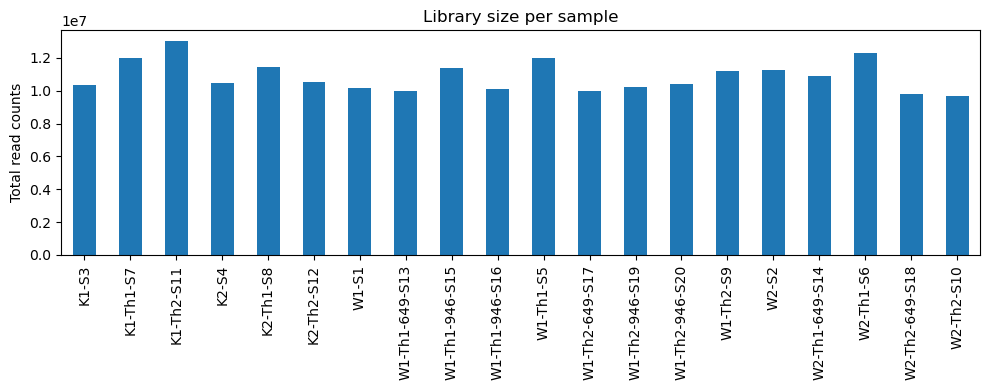

In [3]:
# --- Re-import libraries (safe even if already imported)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Make sure we are in the correct directory
import os
os.chdir(r"C:\Users\kumbh\Documents\GSE123966_RNAseq")

# --- Reload the raw file
counts = pd.read_csv(
    "data/GSE123966_ReverseStrandedCounts-withNames-proteinCoding.txt",
    sep="\t"
)

# --- Clean the table
counts_clean = counts.set_index("Gene.Name")
counts_clean = counts_clean.drop(columns=["Gene.ID", "Chrom", "Biotype"])

# --- Collapse duplicate gene names
counts_final = counts_clean.groupby(counts_clean.index).sum()

# --- Compute library sizes
library_sizes = counts_final.sum()

# --- Plot library sizes
plt.figure(figsize=(10, 4))
library_sizes.plot(kind="bar")
plt.ylabel("Total read counts")
plt.title("Library size per sample")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


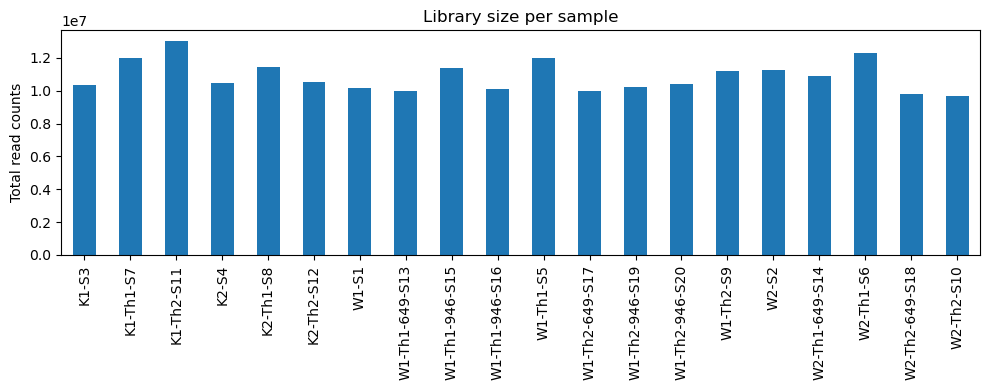

In [4]:
# Save the library size QC plot
plt.figure(figsize=(10, 4))
library_sizes.plot(kind="bar")
plt.ylabel("Total read counts")
plt.title("Library size per sample")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig("results/library_size_QC.png", dpi=300)
plt.show()


In [5]:
# Make sure results folder exists
import os
os.makedirs("results", exist_ok=True)

# Recreate library sizes (safe)
library_sizes = counts_final.sum()

# Plot and SAVE
plt.figure(figsize=(10, 4))
library_sizes.plot(kind="bar")
plt.ylabel("Total read counts")
plt.title("Library size per sample")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig("results/library_size_QC.png", dpi=300)
plt.close()

print("File saved: results/library_size_QC.png")


File saved: results/library_size_QC.png


In [6]:
# Log2 transformation
log_counts = np.log2(counts_final + 1)

log_counts.head()


,K1-S3,K1-Th1-S7,K1-Th2-S11,K2-S4,K2-Th1-S8,K2-Th2-S12,W1-S1,W1-Th1-649-S13,W1-Th1-946-S15,W1-Th1-946-S16,W1-Th1-S5,W1-Th2-649-S17,W1-Th2-946-S19,W1-Th2-946-S20,W1-Th2-S9,W2-S2,W2-Th1-649-S14,W2-Th1-S6,W2-Th2-649-S18,W2-Th2-S10
Gene.Name,,,,,,,,,,,,,,,,,,,,
0610007P14Rik,8.134426,10.172428,9.754888,8.224002,9.917372,9.679480,7.988685,9.049849,9.131857,9.194757,9.396605,9.199672,9.245553,9.663558,9.287712,8.027906,9.328675,9.342075,9.918863,9.326429
0610009B22Rik,5.523562,7.417853,6.523562,5.129283,7.129283,6.149747,4.700440,6.442943,6.700440,6.357552,6.442943,6.044394,5.727920,6.507795,5.930737,4.169925,6.426265,6.643856,6.209453,6.169925
0610009L18Rik,3.584963,4.000000,4.584963,3.459432,3.906891,4.169925,3.906891,3.169925,2.807355,3.700440,3.169925,2.321928,3.169925,3.584963,2.807355,3.807355,2.807355,4.169925,3.000000,3.169925
0610009O20Rik,9.060696,8.665336,8.754888,9.144658,8.851749,8.531381,8.816984,8.764872,8.744834,8.758223,8.873444,8.965784,8.829723,8.861087,8.997179,9.052568,8.873444,9.082149,8.741467,8.921841
0610010F05Rik,7.417853,8.741467,7.774787,7.451211,8.523562,7.409391,6.870365,6.643856,6.794416,7.022368,7.139551,6.714246,6.977280,7.312883,6.658211,6.942515,7.011227,7.098032,7.882643,6.794416


In [7]:
from sklearn.decomposition import PCA

# PCA on samples (transpose required)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(log_counts.T)

# Create PCA dataframe
pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"],
    index=log_counts.columns
)

pca_df


,PC1,PC2
K1-S3,140.824840,30.216966
K1-Th1-S7,-26.424252,-59.196980
K1-Th2-S11,-56.866120,48.207171
K2-S4,137.387585,23.346427
K2-Th1-S8,-24.669818,-58.865351
K2-Th2-S12,-44.979258,38.864889
W1-S1,151.468024,24.394371
W1-Th1-649-S13,-11.711365,-61.136941
W1-Th1-946-S15,-17.848509,-61.169788
W1-Th1-946-S16,-17.928337,-59.770860


In [9]:
# Recreate sample metadata
samples = log_counts.columns

sample_info = []

for s in samples:
    genotype = "KO" if s.startswith("K") else "WT"
    
    if "Th1" in s:
        condition = "Th1"
    elif "Th2" in s:
        condition = "Th2"
    else:
        condition = "Naive"
    
    sample_info.append([s, genotype, condition])

sample_metadata = pd.DataFrame(
    sample_info,
    columns=["Sample", "Genotype", "Condition"]
)

# Merge PCA with metadata
pca_plot_df = pca_df.merge(
    sample_metadata,
    left_index=True,
    right_on="Sample"
)

pca_plot_df


,PC1,PC2,Sample,Genotype,Condition
0,140.824840,30.216966,K1-S3,KO,Naive
1,-26.424252,-59.196980,K1-Th1-S7,KO,Th1
2,-56.866120,48.207171,K1-Th2-S11,KO,Th2
3,137.387585,23.346427,K2-S4,KO,Naive
4,-24.669818,-58.865351,K2-Th1-S8,KO,Th1
5,-44.979258,38.864889,K2-Th2-S12,KO,Th2
6,151.468024,24.394371,W1-S1,WT,Naive
7,-11.711365,-61.136941,W1-Th1-649-S13,WT,Th1
8,-17.848509,-61.169788,W1-Th1-946-S15,WT,Th1
9,-17.928337,-59.770860,W1-Th1-946-S16,WT,Th1


In [10]:
import numpy as np

log_counts = np.log2(counts_final + 1)


In [11]:
from sklearn.decomposition import PCA
import pandas as pd

# PCA on samples (transpose!)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(log_counts.T)

# Create PCA dataframe
pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"],
    index=log_counts.columns
)


In [12]:
samples = log_counts.columns

sample_info = []
for s in samples:
    genotype = "KO" if s.startswith("K") else "WT"
    
    if "Th1" in s:
        condition = "Th1"
    elif "Th2" in s:
        condition = "Th2"
    else:
        condition = "Naive"
    
    sample_info.append([s, genotype, condition])

sample_metadata = pd.DataFrame(
    sample_info,
    columns=["Sample", "Genotype", "Condition"]
)


In [13]:
pca_plot_df = pca_df.merge(
    sample_metadata,
    left_index=True,
    right_on="Sample"
)


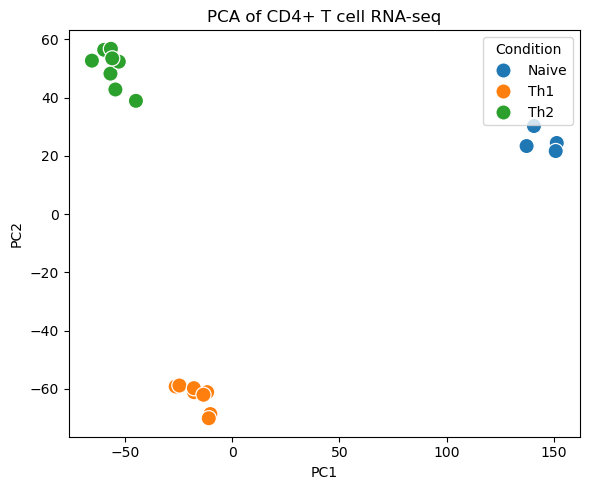

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Condition",
    s=120
)

plt.title("PCA of CD4+ T cell RNA-seq")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


In [15]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Condition",
    s=120
)

plt.title("PCA of CD4+ T cell RNA-seq")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Condition")
plt.tight_layout()
plt.savefig("results/PCA_Naive_Th1_Th2.png", dpi=300)
plt.close()


In [16]:
# Select only Naive and Th1 samples
naive_th1_samples = sample_metadata[
    sample_metadata["Condition"].isin(["Naive", "Th1"])
]

naive_th1_samples


,Sample,Genotype,Condition
0,K1-S3,KO,Naive
1,K1-Th1-S7,KO,Th1
3,K2-S4,KO,Naive
4,K2-Th1-S8,KO,Th1
6,W1-S1,WT,Naive
7,W1-Th1-649-S13,WT,Th1
8,W1-Th1-946-S15,WT,Th1
9,W1-Th1-946-S16,WT,Th1
10,W1-Th1-S5,WT,Th1
15,W2-S2,WT,Naive


In [17]:
# Get sample names for Naive vs Th1
naive_th1_sample_names = naive_th1_samples["Sample"].tolist()

# Subset log-transformed counts
log_counts_naive_th1 = log_counts[naive_th1_sample_names]

log_counts_naive_th1.shape


(21992, 12)

In [18]:
# Create condition labels in the same order as columns
group_labels = naive_th1_samples.set_index("Sample").loc[
    log_counts_naive_th1.columns, "Condition"
]

group_labels


K1-S3             Naive
K1-Th1-S7           Th1
K2-S4             Naive
K2-Th1-S8           Th1
W1-S1             Naive
W1-Th1-649-S13      Th1
W1-Th1-946-S15      Th1
W1-Th1-946-S16      Th1
W1-Th1-S5           Th1
W2-S2             Naive
W2-Th1-649-S14      Th1
W2-Th1-S6           Th1
Name: Condition, dtype: object

In [19]:
from scipy.stats import ttest_ind

# Separate samples by condition
naive_samples = group_labels[group_labels == "Naive"].index
th1_samples = group_labels[group_labels == "Th1"].index

# Compute means
mean_naive = log_counts_naive_th1[naive_samples].mean(axis=1)
mean_th1 = log_counts_naive_th1[th1_samples].mean(axis=1)

# Log2 fold change (Th1 vs Naive)
log2fc = mean_th1 - mean_naive

# Perform t-test for each gene
pvals = []
for gene in log_counts_naive_th1.index:
    naive_vals = log_counts_naive_th1.loc[gene, naive_samples]
    th1_vals = log_counts_naive_th1.loc[gene, th1_samples]
    
    stat, pval = ttest_ind(th1_vals, naive_vals, equal_var=False)
    pvals.append(pval)

# Create DE results table
de_naive_vs_th1 = pd.DataFrame({
    "mean_Naive": mean_naive,
    "mean_Th1": mean_th1,
    "log2FC": log2fc,
    "pvalue": pvals
})

de_naive_vs_th1.head()


C:\Users\kumbh\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,mean_Naive,mean_Th1,log2FC,pvalue
Gene.Name,,,,
0610007P14Rik,8.093755,9.441702,1.347947,0.000010
0610009B22Rik,4.880802,6.695142,1.814339,0.003698
0610009L18Rik,3.689660,3.466477,-0.223183,0.330358
0610009O20Rik,9.018726,8.826756,-0.191970,0.064631
0610010F05Rik,7.170486,7.371810,0.201324,0.544682


In [20]:
from statsmodels.stats.multitest import multipletests

# Adjust p-values using FDR
de_naive_vs_th1["padj"] = multipletests(
    de_naive_vs_th1["pvalue"],
    method="fdr_bh"
)[1]

de_naive_vs_th1.head()


,mean_Naive,mean_Th1,log2FC,pvalue,padj
Gene.Name,,,,,
0610007P14Rik,8.093755,9.441702,1.347947,0.000010,NaN
0610009B22Rik,4.880802,6.695142,1.814339,0.003698,NaN
0610009L18Rik,3.689660,3.466477,-0.223183,0.330358,NaN
0610009O20Rik,9.018726,8.826756,-0.191970,0.064631,NaN
0610010F05Rik,7.170486,7.371810,0.201324,0.544682,NaN


In [21]:
# Drop genes with NaN p-values
de_naive_vs_th1_clean = de_naive_vs_th1.dropna(subset=["pvalue"])

from statsmodels.stats.multitest import multipletests

# Recalculate adjusted p-values
de_naive_vs_th1_clean["padj"] = multipletests(
    de_naive_vs_th1_clean["pvalue"],
    method="fdr_bh"
)[1]

de_naive_vs_th1_clean.head()


C:\Users\kumbh\AppData\Local\Temp\ipykernel_26648\392056703.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  de_naive_vs_th1_clean["padj"] = multipletests(


,mean_Naive,mean_Th1,log2FC,pvalue,padj
Gene.Name,,,,,
0610007P14Rik,8.093755,9.441702,1.347947,0.000010,0.000146
0610009B22Rik,4.880802,6.695142,1.814339,0.003698,0.010962
0610009L18Rik,3.689660,3.466477,-0.223183,0.330358,0.430362
0610009O20Rik,9.018726,8.826756,-0.191970,0.064631,0.112267
0610010F05Rik,7.170486,7.371810,0.201324,0.544682,0.615506


In [22]:
# Define significance thresholds
sig_genes = de_naive_vs_th1_clean[
    (de_naive_vs_th1_clean["padj"] < 0.05) &
    (abs(de_naive_vs_th1_clean["log2FC"]) >= 1)
]

sig_genes.shape


(4190, 5)

C:\Users\kumbh\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


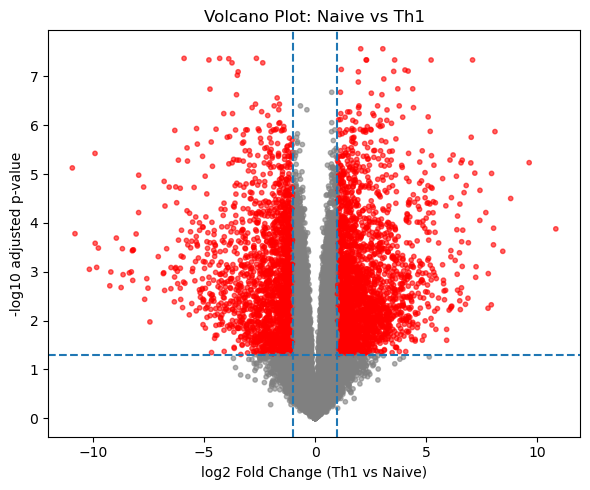

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Prepare data
de_plot = de_naive_vs_th1_clean.copy()
de_plot["neg_log10_padj"] = -np.log10(de_plot["padj"])

# Define significance
de_plot["Significant"] = (
    (de_plot["padj"] < 0.05) &
    (abs(de_plot["log2FC"]) >= 1)
)

# Plot
plt.figure(figsize=(6, 5))

plt.scatter(
    de_plot["log2FC"],
    de_plot["neg_log10_padj"],
    c=de_plot["Significant"].map({True: "red", False: "grey"}),
    alpha=0.6,
    s=10
)

plt.axvline(1, linestyle="--")
plt.axvline(-1, linestyle="--")
plt.axhline(-np.log10(0.05), linestyle="--")

plt.xlabel("log2 Fold Change (Th1 vs Naive)")
plt.ylabel("-log10 adjusted p-value")
plt.title("Volcano Plot: Naive vs Th1")

plt.tight_layout()
plt.show()


In [24]:
# Ensure results folder exists
import os
os.makedirs("results", exist_ok=True)

# Prepare data for plotting
de_plot = de_naive_vs_th1_clean.copy()
de_plot["neg_log10_padj"] = -np.log10(de_plot["padj"])
de_plot["Significant"] = (
    (de_plot["padj"] < 0.05) &
    (abs(de_plot["log2FC"]) >= 1)
)

# Create and SAVE volcano plot
plt.figure(figsize=(6, 5))

plt.scatter(
    de_plot["log2FC"],
    de_plot["neg_log10_padj"],
    c=de_plot["Significant"].map({True: "red", False: "grey"}),
    alpha=0.6,
    s=10
)

plt.axvline(1, linestyle="--")
plt.axvline(-1, linestyle="--")
plt.axhline(-np.log10(0.05), linestyle="--")

plt.xlabel("log2 Fold Change (Th1 vs Naive)")
plt.ylabel("-log10 adjusted p-value")
plt.title("Volcano Plot: Naive vs Th1")

plt.tight_layout()
plt.savefig("results/Volcano_Naive_vs_Th1.png", dpi=300)
plt.close()

print("Saved: results/Volcano_Naive_vs_Th1.png")


C:\Users\kumbh\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


Saved: results/Volcano_Naive_vs_Th1.png


In [25]:
# Select only Naive and Th2 samples
naive_th2_samples = sample_metadata[
    sample_metadata["Condition"].isin(["Naive", "Th2"])
]

naive_th2_samples


,Sample,Genotype,Condition
0,K1-S3,KO,Naive
2,K1-Th2-S11,KO,Th2
3,K2-S4,KO,Naive
5,K2-Th2-S12,KO,Th2
6,W1-S1,WT,Naive
11,W1-Th2-649-S17,WT,Th2
12,W1-Th2-946-S19,WT,Th2
13,W1-Th2-946-S20,WT,Th2
14,W1-Th2-S9,WT,Th2
15,W2-S2,WT,Naive


In [26]:
# Get sample names for Naive vs Th2
naive_th2_sample_names = naive_th2_samples["Sample"].tolist()

# Subset log-transformed counts
log_counts_naive_th2 = log_counts[naive_th2_sample_names]

log_counts_naive_th2.shape


(21992, 12)

In [27]:
# Create condition labels aligned with expression columns
group_labels_th2 = naive_th2_samples.set_index("Sample").loc[
    log_counts_naive_th2.columns, "Condition"
]

group_labels_th2


K1-S3             Naive
K1-Th2-S11          Th2
K2-S4             Naive
K2-Th2-S12          Th2
W1-S1             Naive
W1-Th2-649-S17      Th2
W1-Th2-946-S19      Th2
W1-Th2-946-S20      Th2
W1-Th2-S9           Th2
W2-S2             Naive
W2-Th2-649-S18      Th2
W2-Th2-S10          Th2
Name: Condition, dtype: object

In [28]:
from scipy.stats import ttest_ind

# Separate samples by condition
naive_samples_th2 = group_labels_th2[group_labels_th2 == "Naive"].index
th2_samples = group_labels_th2[group_labels_th2 == "Th2"].index

# Compute mean expression
mean_naive_th2 = log_counts_naive_th2[naive_samples_th2].mean(axis=1)
mean_th2 = log_counts_naive_th2[th2_samples].mean(axis=1)

# Log2 fold change (Th2 vs Naive)
log2fc_th2 = mean_th2 - mean_naive_th2

# Perform t-test for each gene
pvals_th2 = []
for gene in log_counts_naive_th2.index:
    naive_vals = log_counts_naive_th2.loc[gene, naive_samples_th2]
    th2_vals = log_counts_naive_th2.loc[gene, th2_samples]
    
    stat, pval = ttest_ind(th2_vals, naive_vals, equal_var=False)
    pvals_th2.append(pval)

# Create DE results table
de_naive_vs_th2 = pd.DataFrame({
    "mean_Naive": mean_naive_th2,
    "mean_Th2": mean_th2,
    "log2FC": log2fc_th2,
    "pvalue": pvals_th2
})

de_naive_vs_th2.head()


C:\Users\kumbh\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


,mean_Naive,mean_Th2,log2FC,pvalue
Gene.Name,,,,
0610007P14Rik,8.093755,9.509519,1.415765,2.020338e-07
0610009B22Rik,4.880802,6.157942,1.277139,1.674816e-02
0610009L18Rik,3.689660,3.351123,-0.338537,2.572204e-01
0610009O20Rik,9.018726,8.825419,-0.193308,6.754105e-02
0610010F05Rik,7.170486,7.190482,0.019996,9.320417e-01


In [30]:
from statsmodels.stats.multitest import multipletests

# Recreate cleaned DE table with FDR
de_naive_vs_th2_clean = de_naive_vs_th2.dropna(subset=["pvalue"])

de_naive_vs_th2_clean["padj"] = multipletests(
    de_naive_vs_th2_clean["pvalue"],
    method="fdr_bh"
)[1]

# Identify significant genes
sig_genes_th2 = de_naive_vs_th2_clean[
    (de_naive_vs_th2_clean["padj"] < 0.05) &
    (abs(de_naive_vs_th2_clean["log2FC"]) >= 1)
]

sig_genes_th2.shape


C:\Users\kumbh\AppData\Local\Temp\ipykernel_26648\2008095118.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  de_naive_vs_th2_clean["padj"] = multipletests(


(4952, 5)

C:\Users\kumbh\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


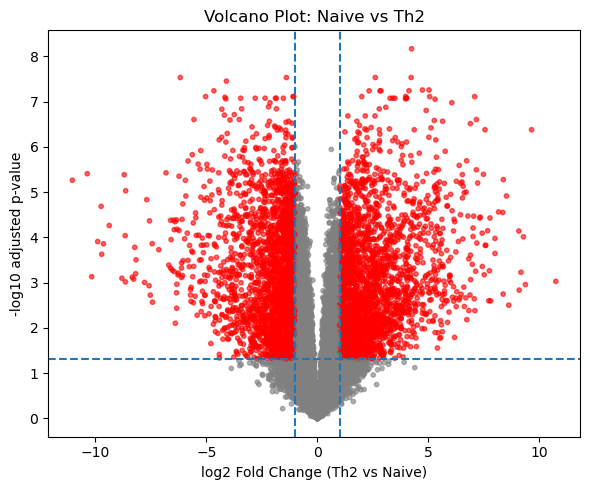

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Prepare data for plotting
de_plot_th2 = de_naive_vs_th2_clean.copy()
de_plot_th2["neg_log10_padj"] = -np.log10(de_plot_th2["padj"])

# Define significance
de_plot_th2["Significant"] = (
    (de_plot_th2["padj"] < 0.05) &
    (abs(de_plot_th2["log2FC"]) >= 1)
)

# Plot
plt.figure(figsize=(6, 5))

plt.scatter(
    de_plot_th2["log2FC"],
    de_plot_th2["neg_log10_padj"],
    c=de_plot_th2["Significant"].map({True: "red", False: "grey"}),
    alpha=0.6,
    s=10
)

plt.axvline(1, linestyle="--")
plt.axvline(-1, linestyle="--")
plt.axhline(-np.log10(0.05), linestyle="--")

plt.xlabel("log2 Fold Change (Th2 vs Naive)")
plt.ylabel("-log10 adjusted p-value")
plt.title("Volcano Plot: Naive vs Th2")

plt.tight_layout()
plt.show()


C:\Users\kumbh\anaconda3\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


NameError: name 'pl' is not defined

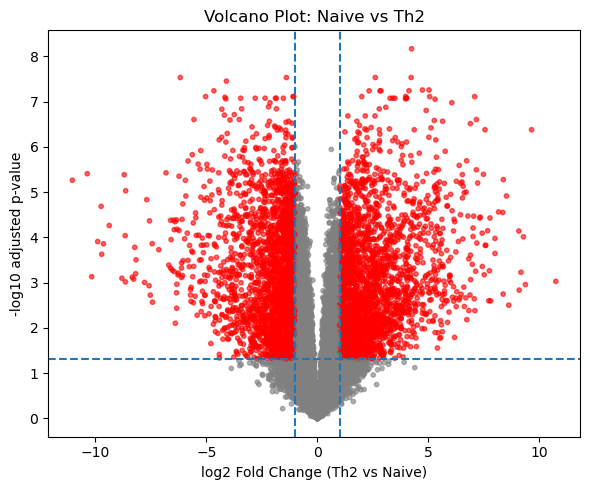

In [32]:
# Ensure results folder exists
import os
os.makedirs("results", exist_ok=True)

# Prepare data for plotting
de_plot_th2 = de_naive_vs_th2_clean.copy()
de_plot_th2["neg_log10_padj"] = -np.log10(de_plot_th2["padj"])

de_plot_th2["Significant"] = (
    (de_plot_th2["padj"] < 0.05) &
    (abs(de_plot_th2["log2FC"]) >= 1)
)

# Create and SAVE volcano plot
plt.figure(figsize=(6, 5))

plt.scatter(
    de_plot_th2["log2FC"],
    de_plot_th2["neg_log10_padj"],
    c=de_plot_th2["Significant"].map({True: "red", False: "grey"}),
    alpha=0.6,
    s=10
)

plt.axvline(1, linestyle="--")
plt.axvline(-1, linestyle="--")
plt.axhline(-np.log10(0.05), linestyle="--")

plt.xlabel("log2 Fold Change (Th2 vs Naive)")
plt.ylabel("-log10 adjusted p-value")
plt.title("Volcano Plot: Naive vs Th2")

plt.tight_layout()
pl


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Ensure results folder exists
os.makedirs("results", exist_ok=True)

# Prepare data
de_plot_th2 = de_naive_vs_th2_clean.copy()

# Fix zero adjusted p-values
de_plot_th2["padj_fixed"] = de_plot_th2["padj"].replace(0, 1e-300)
de_plot_th2["neg_log10_padj"] = -np.log10(de_plot_th2["padj_fixed"])

# Define significance
de_plot_th2["Significant"] = (
    (de_plot_th2["padj"] < 0.05) &
    (abs(de_plot_th2["log2FC"]) >= 1)
)

# Plot
plt.figure(figsize=(6, 5))

plt.scatter(
    de_plot_th2["log2FC"],
    de_plot_th2["neg_log10_padj"],
    c=de_plot_th2["Significant"].map({True: "red", False: "grey"}),
    alpha=0.6,
    s=10
)

plt.axvline(1, linestyle="--")
plt.axvline(-1, linestyle="--")
plt.axhline(-np.log10(0.05), linestyle="--")

plt.xlabel("log2 Fold Change (Th2 vs Naive)")
plt.ylabel("-log10 adjusted p-value")
plt.title("Volcano Plot: Naive vs Th2")

plt.tight_layout()
plt.savefig("results/Volcano_Naive_vs_Th2.png", dpi=300)
plt.close()

print("Saved successfully: results/Volcano_Naive_vs_Th2.png")


Saved successfully: results/Volcano_Naive_vs_Th2.png


In [34]:
# Select top genes from each comparison
top_th1_genes = (
    de_naive_vs_th1_clean
    .sort_values("padj")
    .head(50)
    .index
)

top_th2_genes = (
    de_naive_vs_th2_clean
    .sort_values("padj")
    .head(50)
    .index
)

# Combine and make unique
top_genes = list(set(top_th1_genes).union(set(top_th2_genes)))

len(top_genes)


93

In [35]:
from sklearn.preprocessing import StandardScaler

# Extract expression for top genes
heatmap_data = log_counts.loc[top_genes]

# Z-score per gene
scaler = StandardScaler()
heatmap_scaled = pd.DataFrame(
    scaler.fit_transform(heatmap_data.T).T,
    index=heatmap_data.index,
    columns=heatmap_data.columns
)

heatmap_scaled.shape


(93, 20)

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Ensure results folder exists
os.makedirs("results", exist_ok=True)

plt.figure(figsize=(10, 12))

sns.clustermap(
    heatmap_scaled,
    cmap="vlag",
    col_cluster=True,
    row_cluster=True,
    yticklabels=False,
    figsize=(10, 12)
)

plt.savefig("results/Heatmap_Top_DE_Genes.png", dpi=300)
plt.close()

print("Saved: results/Heatmap_Top_DE_Genes.png")


Saved: results/Heatmap_Top_DE_Genes.png


<Figure size 1000x1200 with 0 Axes>

In [37]:
!pip install gseapy


  Using cached gseapy-1.1.11-cp313-cp313-win_amd64.whl.metadata (12 kB)


In [38]:
import gseapy as gp


In [39]:
# Get significantly UPREGULATED genes in Th1
th1_up_genes = sig_genes[
    sig_genes["log2FC"] > 0
].index.tolist()

len(th1_up_genes)


2332

In [40]:
# Run pathway enrichment for Th1 upregulated genes
th1_enrich = gp.enrichr(
    gene_list=th1_up_genes,
    organism="Mouse",
    gene_sets=[
        "KEGG_2021_Mouse",
        "Reactome_2022",
        "GO_Biological_Process_2021"
    ],
    cutoff=0.05
)

# View top results
th1_enrich.results.head(10)


2026-01-03 18:52:30,040 [WARNING] Input library not found: KEGG_2021_Mouse. Skip
2026-01-03 18:52:30,526 [ERROR] Gene set GO_Biological_Process_2021 generated an exception: Network error sending gene list: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))
2026-01-03 18:52:30,573 [ERROR] Gene set Reactome_2022 generated an exception: Network error sending gene list: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))
2026-01-03 18:52:30,576 [ERROR] No hits returned for all input gene sets!


AttributeError: 'list' object has no attribute 'head'

In [41]:
# Use top 300 Th1 upregulated genes (most informative)
th1_top300 = (
    sig_genes
    .sort_values("log2FC", ascending=False)
    .head(300)
    .index
    .tolist()
)

len(th1_top300)


300

In [43]:
import gseapy as gp

libs = gp.get_library_name(organism="Mouse")
libs


['ARCHS4_Cell-lines',
 'ARCHS4_IDG_Coexp',
 'ARCHS4_Kinases_Coexp',
 'ARCHS4_TFs_Coexp',
 'ARCHS4_Tissues',
 'Achilles_fitness_decrease',
 'Achilles_fitness_increase',
 'Aging_Perturbations_from_GEO_down',
 'Aging_Perturbations_from_GEO_up',
 'Allen_Brain_Atlas_10x_scRNA_2021',
 'Allen_Brain_Atlas_down',
 'Allen_Brain_Atlas_up',
 'Azimuth_2023',
 'Azimuth_Cell_Types_2021',
 'BioCarta_2013',
 'BioCarta_2015',
 'BioCarta_2016',
 'BioPlanet_2019',
 'BioPlex_2017',
 'CCLE_Proteomics_2020',
 'CM4AI_U2OS_Protein_Localization_Assemblies',
 'COMPARTMENTS_Curated_2025',
 'COMPARTMENTS_Experimental_2025',
 'CORUM',
 'COVID-19_Related_Gene_Sets',
 'COVID-19_Related_Gene_Sets_2021',
 'Cancer_Cell_Line_Encyclopedia',
 'CellMarker_2024',
 'CellMarker_Augmented_2021',
 'ChEA_2013',
 'ChEA_2015',
 'ChEA_2016',
 'ChEA_2022',
 'Chromosome_Location',
 'Chromosome_Location_hg19',
 'ClinVar_2019',
 'ClinVar_2025',
 'DGIdb_Drug_Targets_2024',
 'DSigDB',
 'Data_Acquisition_Method_Most_Popular_Genes',
 'DepMa

In [44]:
import gseapy as gp

# Run enrichment with confirmed libraries
th1_enrich = gp.enrichr(
    gene_list=th1_top300,
    organism="Mouse",
    gene_sets=[
        "GO_Biological_Process_2021",
        "Reactome_2022",
        "KEGG_2019_Mouse"
    ],
    cutoff=0.05
)

# Show top results
th1_enrich.results.head(15)


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,Reactome_2022,Cytokine-cytokine receptor interaction,21/292,3.573251e-09,8.111280e-07,0,0,5.396302,104.956941,CCR1;IL21;IL10;CSF2;CSF1;IL1R2;TNFRSF9;IL13;CX...
1,Reactome_2022,Amoebiasis,9/106,3.136544e-05,3.559977e-03,0,0,6.250292,64.814306,IL10;LAMA5;CSF2;MUC2;IFNG;NOS2;IL1R2;LAMC2;SER...
2,Reactome_2022,Chemokine signaling pathway,10/197,8.130620e-04,5.158753e-02,0,0,3.598193,25.600074,CCR1;CXCR1;NCF1;CXCR2;CCL4;CCL3;GNB5;CCR5;CXCL...
3,Reactome_2022,Salmonella infection,6/78,1.125814e-03,5.158753e-02,0,0,5.563492,37.771935,CSF2;IFNG;NOS2;CCL4;CCL3;CXCL3
4,Reactome_2022,Biosynthesis of unsaturated fatty acids,4/32,1.281279e-03,5.158753e-02,0,0,9.494208,63.230444,FADS2;SCD2;ACAA1B;SCD1
5,Reactome_2022,ECM-receptor interaction,6/83,1.554565e-03,5.158753e-02,0,0,5.200901,33.631937,LAMA5;SDC4;ITGA3;ITGA11;SPP1;LAMC2
6,Reactome_2022,Fructose and mannose metabolism,4/35,1.801024e-03,5.158753e-02,0,0,8.574106,54.183207,TPI1;ALDOC;HK2;AKR1B8
7,Reactome_2022,Inflammatory bowel disease (IBD),5/59,1.897009e-03,5.158753e-02,0,0,6.166353,38.647473,IL21;IL10;IFNG;IL13;IL12RB2
8,Reactome_2022,"Neomycin, kanamycin and gentamicin biosynthesis",2/5,2.176477e-03,5.158753e-02,0,0,44.064877,270.119803,HK2;GCK
9,Reactome_2022,Calcium signaling pathway,9/189,2.272578e-03,5.158753e-02,0,0,3.353952,20.414969,MYLK2;CYSLTR2;NOS2;P2RX3;ADORA2B;ATP2B4;MYLK;S...


In [45]:
import os

# Ensure results folder exists
os.makedirs("results", exist_ok=True)

# Save Reactome enrichment results
th1_enrich.results.to_csv(
    "results/Th1_Pathway_Enrichment_Reactome.csv",
    index=False
)

th1_enrich.results.to_excel(
    "results/Th1_Pathway_Enrichment_Reactome.xlsx",
    index=False
)

print("Saved:")
print(" - results/Th1_Pathway_Enrichment_Reactome.csv")
print(" - results/Th1_Pathway_Enrichment_Reactome.xlsx")


Saved:
 - results/Th1_Pathway_Enrichment_Reactome.csv
 - results/Th1_Pathway_Enrichment_Reactome.xlsx


In [46]:
# Get significantly UPREGULATED genes in Th2
th2_up_genes = sig_genes_th2[
    sig_genes_th2["log2FC"] > 0
].index.tolist()

len(th2_up_genes)


2546

In [47]:
# Select top 300 Th2-upregulated genes
th2_top300 = (
    sig_genes_th2
    .sort_values("log2FC", ascending=False)
    .head(300)
    .index
    .tolist()
)

len(th2_top300)


300

In [48]:
import gseapy as gp

# Run enrichment for Th2 upregulated genes
th2_enrich = gp.enrichr(
    gene_list=th2_top300,
    organism="Mouse",
    gene_sets=[
        "GO_Biological_Process_2021",
        "Reactome_2022",
        "KEGG_2019_Mouse"
    ],
    cutoff=0.05
)

# View top enriched pathways
th2_enrich.results.head(15)


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2021,Cytokine-cytokine receptor interaction,17/292,0.000002,0.000477,0,0,4.243174,55.278924,CCR1;IL10;TGFB3;IL1R2;TNFRSF9;IL24;IL13;LIF;IN...
1,GO_Biological_Process_2021,HIF-1 signaling pathway,9/104,0.000027,0.002923,0,0,6.382528,67.157180,CDKN1A;EGLN3;NOS2;SERPINE1;EIF4EBP1;PGK1;HK2;E...
2,GO_Biological_Process_2021,Neuroactive ligand-receptor interaction,16/348,0.000079,0.005710,0,0,3.286611,31.048024,GRP;GIPR;PTH;GZMA;HTR1B;ADM;NTS;APLN;GRIN1;CYS...
3,GO_Biological_Process_2021,Central carbon metabolism in cancer,6/64,0.000391,0.021232,0,0,6.911330,54.225336,NTRK1;GLS2;SLC16A3;HK2;EGFR;GCK
4,GO_Biological_Process_2021,JAK-STAT signaling pathway,9/164,0.000850,0.029695,0,0,3.899900,27.574483,IL10;CDKN1A;IL5;IL2RA;IL24;IL13;LIF;EGFR;IL12RB2
5,GO_Biological_Process_2021,Arginine and proline metabolism,5/50,0.000896,0.029695,0,0,7.403013,51.953421,CKMT1;NOS2;P4HA2;PYCR1;AZIN2
6,GO_Biological_Process_2021,PI3K-Akt signaling pathway,14/357,0.001059,0.029695,0,0,2.762523,18.924811,NTRK1;LAMA5;CDKN1A;LAMC2;PPP2R3A;EFNA5;FGF2;EG...
7,GO_Biological_Process_2021,Amoebiasis,7/106,0.001095,0.029695,0,0,4.730134,32.246387,IL10;LAMA5;MUC2;NOS2;TGFB3;IL1R2;LAMC2
8,GO_Biological_Process_2021,Glutamatergic synapse,7/114,0.001670,0.032877,0,0,4.374693,27.974671,PLA2G4E;GLS2;SLC1A1;SLC17A6;CACNA1C;SLC38A3;GRIN1
9,GO_Biological_Process_2021,MAPK signaling pathway,12/294,0.001701,0.032877,0,0,2.869090,18.295587,NTRK1;TGFB3;PLA2G4E;MAPT;CACNA1C;EFNA5;FGF2;DU...


In [49]:
import os

os.makedirs("results", exist_ok=True)

th2_enrich.results.to_csv(
    "results/Th2_Pathway_Enrichment_GO_BP.csv",
    index=False
)

th2_enrich.results.to_excel(
    "results/Th2_Pathway_Enrichment_GO_BP.xlsx",
    index=False
)

print("Saved:")
print(" - results/Th2_Pathway_Enrichment_GO_BP.csv")
print(" - results/Th2_Pathway_Enrichment_GO_BP.xlsx")


Saved:
 - results/Th2_Pathway_Enrichment_GO_BP.csv
 - results/Th2_Pathway_Enrichment_GO_BP.xlsx
